# Part 4: Forecast maps vs observed maps

Station values are interpolated to the 0.05° Bihar grid with inverse-distance weighting (power 2, all stations).

**Model shown:** the final Part 2 model (Sanath's Laplace linear model on `log1p`, smeared mean; validation forecasts in `preds/sanath_laplace_mean.parquet`), next to persistence and the Part 1 ridge.

In [ ]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import baseline as B

np.random.seed(0)
warnings.filterwarnings("ignore")

MODEL_NAME = "Laplace (Part 2)"   # label used in titles and tables
MODEL_PATH = "preds/sanath_laplace_mean.parquet"   # final Part 2 model (Sanath)
# --------------------------------------------------------------------

FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

W, stations = B.load_data()
_, T_val = B.issue_times()
T_tgt = T_val + pd.Timedelta(hours=24)     # 91 noon targets, 1 Sep - 30 Nov
dates = T_tgt.normalize()
grid = pd.read_csv("data/bihar_grid_005deg.csv")
boundary = pd.read_csv("data/bihar_boundary.csv")
print(len(T_tgt), "validation days;", len(grid), "grid cells;", len(stations), "stations")

91 validation days; 3396 grid cells; 468 stations


IDW interpolator (power 2, all stations)

In [12]:
gx = (grid.longitude.to_numpy() - 85.5) * 100.3
gy = (grid.latitude.to_numpy() - 25.7) * 110.6
sxy = stations[["x_km", "y_km"]].to_numpy()
D = np.sqrt((gx[:, None] - sxy[None, :, 0]) ** 2 + (gy[:, None] - sxy[None, :, 1]) ** 2)   # 3396 x 468, km

EPS = 1e-6
Wt = 1.0 / np.maximum(D, EPS) ** 2
on_station = D.min(axis=1) < EPS                      # grid cell sits on a station: use it exactly
Wt[on_station] = (D[on_station] < EPS).astype(float)
Wt /= Wt.sum(axis=1, keepdims=True)

def idw(V):
    """V: (..., 468) station values -> (..., 3396) grid values."""
    return np.asarray(V) @ Wt.T

print("Cells exactly on a station:", int(on_station.sum()))

Cells exactly on a station: 0


Map helper


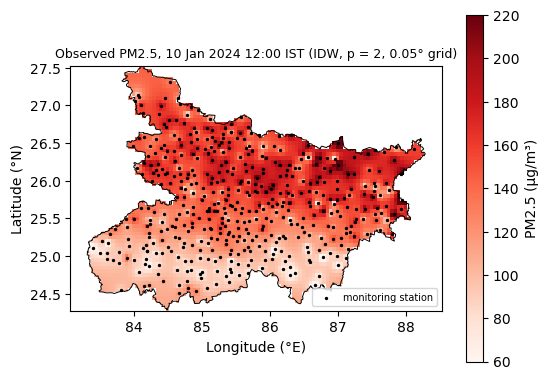

In [13]:
lons = np.round((grid.longitude.to_numpy() - grid.longitude.min()) / 0.05).astype(int)
lats = np.round((grid.latitude.to_numpy() - grid.latitude.min()) / 0.05).astype(int)
lon_axis = grid.longitude.min() + 0.05 * np.arange(lons.max() + 1)
lat_axis = grid.latitude.min() + 0.05 * np.arange(lats.max() + 1)

def to_mesh(m):
    Z = np.full((len(lat_axis), len(lon_axis)), np.nan)
    Z[lats, lons] = m
    return Z

def draw(ax, m, title, vmin, vmax, cmap="Reds"):
    h = ax.pcolormesh(lon_axis, lat_axis, to_mesh(m), cmap=cmap, vmin=vmin, vmax=vmax, shading="nearest")
    ax.plot(boundary.longitude, boundary.latitude, "k-", lw=0.7)
    ax.scatter(stations.longitude, stations.latitude, s=2, c="k", label="monitoring station")
    ax.set_title(title, fontsize=9); ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
    ax.set_aspect(1.0 / np.cos(np.deg2rad(25.7)))
    return h

# Figure-1 style check: observed 10 Jan 2024 12:00 (training period)
t0 = pd.Timestamp("2024-01-10 12:00")
fig, ax = plt.subplots(figsize=(6, 4.5))
h = draw(ax, idw(W.loc[t0].to_numpy()), "Observed PM2.5, 10 Jan 2024 12:00 IST (IDW, p = 2, 0.05° grid)", 60, 220)
fig.colorbar(h, ax=ax, label="PM2.5 (µg/m³)"); ax.legend(loc="lower right", fontsize=7)
plt.show()

 Station-level arrays (91 days x 468 stations)

In [14]:
n_days = len(T_val)
OBS = W.loc[T_tgt].to_numpy()                                   # observed at target
PERS = B.persistence(W, T_val).reshape(n_days, 468)             # reading at issue time

def load_preds(path):
    p = pd.read_parquet(path)
    p.index = pd.to_datetime(p.index).normalize()   # files may label rows 12:00; compare by date
    p.columns = p.columns.astype(str)
    assert p.shape == (n_days, 468), p.shape
    assert list(p.columns) == list(stations.index), "columns must be sensor_id in bihar_stations.csv order"
    assert (p.index == dates).all(), "rows must be the 91 target dates 1 Sep - 30 Nov"
    return np.clip(p.to_numpy(dtype=float), 0, None)

RIDGE = B.part1_ridge_predict(W, stations, T_val).reshape(n_days, 468)
MODEL = RIDGE if MODEL_PATH is None else load_preds(MODEL_PATH)

Metrics: station RMSE, map RMSE, pattern correlation (every validation day)

In [15]:
def daily_metrics(pred):
    Om, Fm = idw(OBS), idw(pred)
    st = np.sqrt(((np.clip(pred, 0, None) - OBS) ** 2).mean(axis=1))
    mp = np.sqrt(((Fm - Om) ** 2).mean(axis=1))
    pc = np.array([np.corrcoef(Fm[i], Om[i])[0, 1] for i in range(len(Om))])
    return pd.DataFrame({"station_rmse": st, "map_rmse": mp, "pattern_corr": pc}, index=dates)

candidates = {"Persistence": PERS, "Ridge (Part 1)": RIDGE}
if MODEL_PATH is not None:
    candidates[MODEL_NAME] = MODEL

daily = {k: daily_metrics(v) for k, v in candidates.items()}
# show only persistence, ridge and the chosen model (MODEL_NAME)
shown = ["Persistence", "Ridge (Part 1)"] + ([MODEL_NAME] if MODEL_NAME not in ("Persistence", "Ridge (Part 1)") else [])
summary = pd.DataFrame({k: {
    "overall station RMSE": np.sqrt(((np.clip(candidates[k], 0, None) - OBS) ** 2).mean()),
    "mean daily station RMSE": d.station_rmse.mean(),
    "mean daily map RMSE": d.map_rmse.mean(),
    "mean pattern corr": d.pattern_corr.mean()} for k, d in daily.items()}).T.round(3)
summary = summary.loc[shown]
assert abs(summary.loc["Persistence", "overall station RMSE"] - 32.75) < 0.01
assert abs(summary.loc["Ridge (Part 1)", "overall station RMSE"] - 29.58) < 0.01
assert not any(d.isna().any().any() for d in daily.values())


## Task 1
Pick three validation days: one clean, one polluted, and the one where your model’s station RMSE was worst. For each, plot side by side: the observed map, your forecast map, the persistence map, and the map of (your forecast−observed). Draw stations and the state outline on top, with one shared colourscale and units.

### Selecting the three days.

In [16]:
net_mean = pd.Series(OBS.mean(axis=1), index=dates)
model_daily = daily[MODEL_NAME] if MODEL_NAME in daily else daily_metrics(MODEL)

picks = {"clean": net_mean.idxmin(), "polluted": net_mean.idxmax(), "worst": model_daily.station_rmse.idxmax()}
pd.DataFrame({k: {"date": d.date(), "network mean obs": net_mean[d], "model station RMSE": model_daily.station_rmse[d],
                  "persistence station RMSE": daily["Persistence"].station_rmse[d]} for k, d in picks.items()}).T.round(2)

,date,network mean obs,model station RMSE,persistence station RMSE
clean,2024-09-15,7.890449,20.079583,27.282976
polluted,2024-11-27,174.969209,62.094719,71.668258
worst,2024-11-29,76.632521,97.241599,112.006204


### Side-by-side maps: observed | forecast | persistence | forecast - observed
The three PM2.5 panels share one colour scale; the difference panel has its own symmetric scale (levels and errors are different quantities).

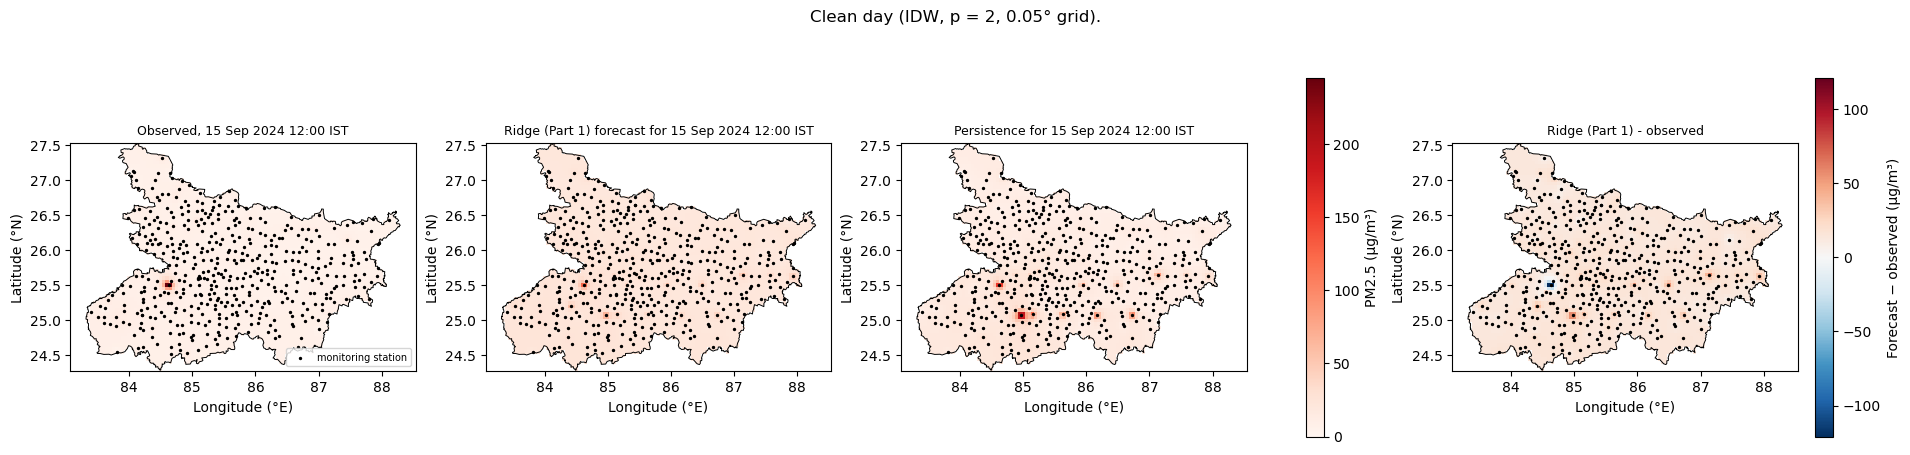

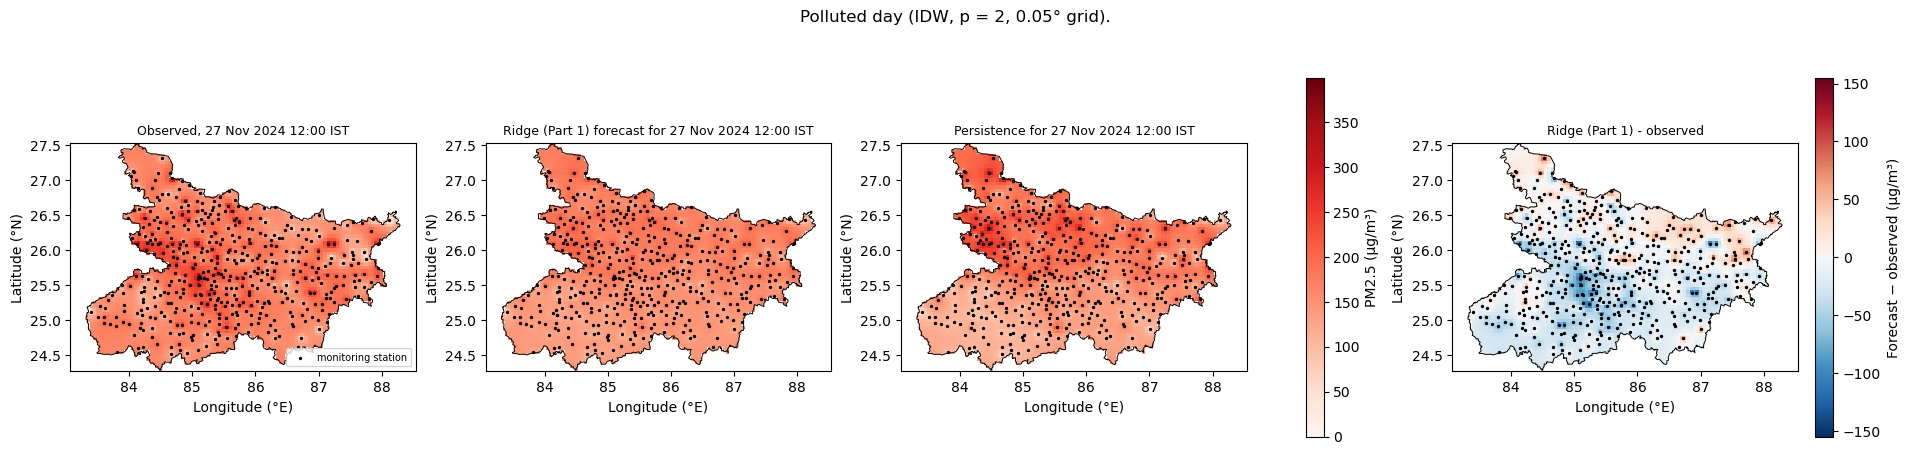

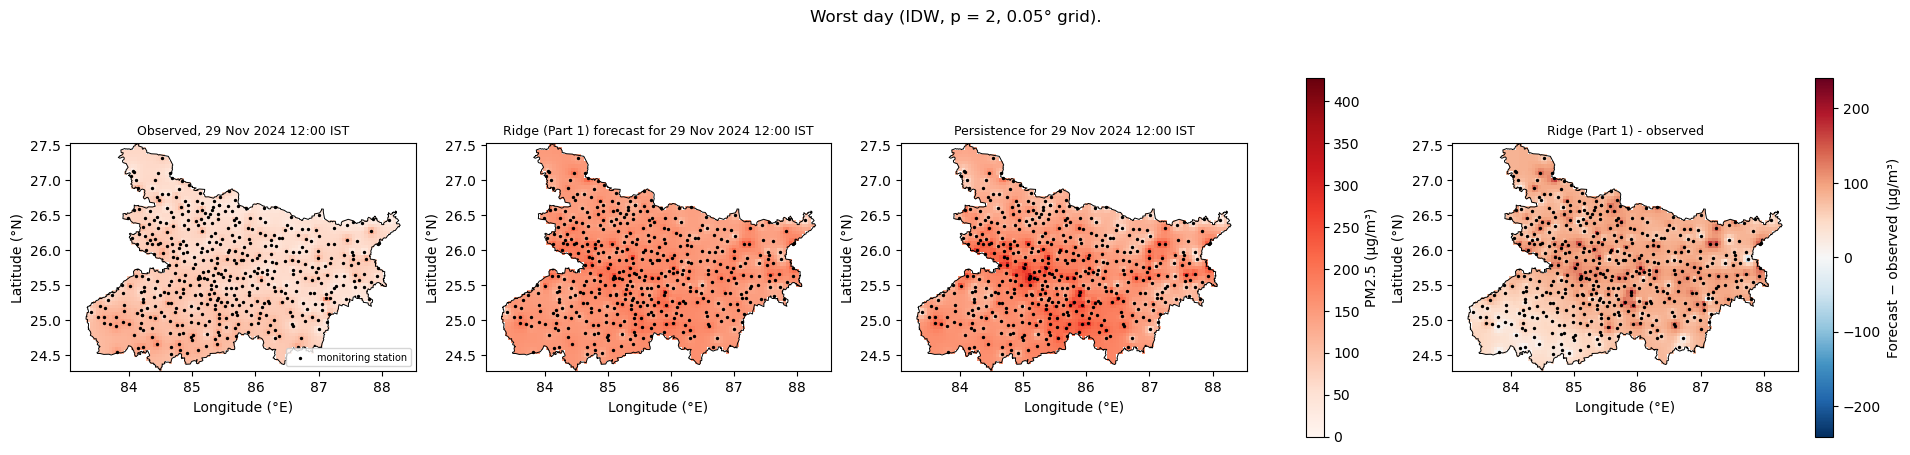

In [17]:
def plot_day(date, tag):
    i = int(np.where(dates == date)[0][0])
    O, F, P = idw(OBS[i]), idw(MODEL[i]), idw(PERS[i])
    vmax = max(np.nanmax(O), np.nanmax(F), np.nanmax(P)); vmin = 0
    dmax = np.nanmax(np.abs(F - O))
    day = f"{date:%d %b %Y} 12:00 IST"
    fig, axs = plt.subplots(1, 4, figsize=(19, 4.8), constrained_layout=True)
    draw(axs[0], O, f"Observed, {day}", vmin, vmax)
    h = draw(axs[1], F, f"{MODEL_NAME} forecast for {day}", vmin, vmax)
    draw(axs[2], P, f"Persistence for {day}", vmin, vmax)
    hd = draw(axs[3], F - O, f"{MODEL_NAME} - observed", -dmax, dmax, cmap="RdBu_r")
    fig.colorbar(h, ax=axs[:3], label="PM2.5 (µg/m³)", shrink=0.8)
    fig.colorbar(hd, ax=axs[3], label="Forecast − observed (µg/m³)", shrink=0.8)
    axs[0].legend(loc="lower right", fontsize=7)
    fig.suptitle(f"{tag.capitalize()} day (IDW, p = 2, 0.05° grid).")
    fig.savefig(FIG_DIR / f"part4_{tag}.png", dpi=150)
    plt.show()

for tag, d in picks.items():
    plot_day(d, tag)

## Task 2
For every validation day, compute: (a) map RMSE, the grid-cell difference between forecast and observed maps; (b) pattern correlation,the correlation across grid cells between the two maps. Report the averages for persistence and for your model, next to their station
RMSE.

### Metrics for every validation day:

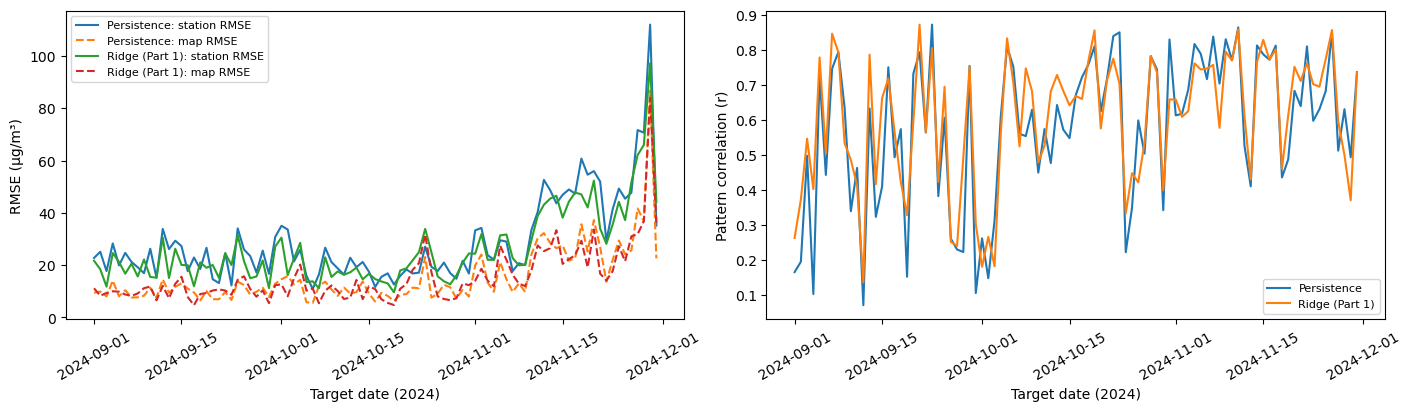

In [18]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4), constrained_layout=True)
for name in ["Persistence", MODEL_NAME]:
    d = daily[name] if name in daily else model_daily
    axs[0].plot(d.index, d.station_rmse, label=f"{name}: station RMSE")
    axs[0].plot(d.index, d.map_rmse, "--", label=f"{name}: map RMSE")
    axs[1].plot(d.index, d.pattern_corr, label=name)
axs[0].set_ylabel("RMSE (µg/m³)"); axs[0].legend(fontsize=8)
axs[1].set_ylabel("Pattern correlation (r)"); axs[1].legend(fontsize=8)
for a in axs: a.set_xlabel("Target date (2024)"); a.tick_params(axis="x", rotation=30)
fig.savefig(FIG_DIR / "part4_daily_metrics.png", dpi=150); plt.show()

### Comparison:

In [19]:
summary

,overall station RMSE,mean daily station RMSE,mean daily map RMSE,mean pattern corr
Persistence,32.745,28.568,15.369,0.580
Ridge (Part 1),29.584,26.001,15.419,0.605


## Answers 

**Which RMSE is better, map or station? Which to quote?**
For our model (Laplace, Part 2) the mean daily map RMSE is 13.84 µg/m³ against a mean daily station RMSE of 24.75 (overall station RMSE 28.16); for persistence 15.37 against 28.57 (overall 32.75). Map RMSE is about half the station RMSE: IDW is a smoothing average, so independent station-level errors partly cancel. That lower number is partly an artefact of interpolation, not better forecasting. Quote the **station RMSE** as forecast accuracy: it is checked against real readings and cannot be flattered by smoothing. Map RMSE is useful partcularly for judging the spatial picture.

**In what sense is the observed map not ground truth?**
It is an IDW interpolation of 468 point sensors: between stations it is just a distance-weighted average, so it cannot represent local values that lie between sensors. The sensors themselves are low-cost and some readings were gap-filled upstream, so even the station values are not exact. Therefore, the observed map is not the ground truth.

**Describe a forecast that has a good pattern correlation but a poor RMSE. Good pattern correlation or poor RMSE, which matters more for a public warning?**
A forecast that gets the spatial *shape* right (the north and east more polluted than the south-west) but is biased by, say, +40 µg/m³ everywhere has a high correlation and a large RMSE. For a public warning the **absolute level** matters more, because health advice and alert bands are tied to concentration thresholds.